In [ ]:
from google.colab import files

uploaded = files.upload()


Saving demo_bacteria_antibiotic_resistance.csv to demo_bacteria_antibiotic_resistance.csv


In [ ]:
import pandas as pd

df = pd.read_csv('demo_bacteria_antibiotic_resistance.csv')

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (1800, 7)

Column Names:
['sample_id', 'bacteria', 'antibiotic', 'specimen_type', 'country', 'collection_year', 'resistance_status']

First 5 Rows:


,sample_id,bacteria,antibiotic,specimen_type,country,collection_year,resistance_status
0,DEMO00001,Salmonella enterica,Ceftriaxone,Sputum,Brazil,2024,Sensitive
1,DEMO00002,Klebsiella pneumoniae,Gentamicin,Wound,India,2023,Sensitive
2,DEMO00003,Salmonella enterica,Ampicillin,Blood,Brazil,2023,Resistant
3,DEMO00004,Staphylococcus aureus,Gentamicin,Blood,United Kingdom,2022,Sensitive
4,DEMO00005,Escherichia coli,Tetracycline,Wound,Brazil,2018,Resistant


In [ ]:
import pandas as pd

df = pd.read_csv('demo_bacteria_antibiotic_resistance.csv')

print("Dataset Shape:", df.shape)
print(df.columns.tolist())
display(df.head())

Dataset Shape: (1800, 7)
['sample_id', 'bacteria', 'antibiotic', 'specimen_type', 'country', 'collection_year', 'resistance_status']


,sample_id,bacteria,antibiotic,specimen_type,country,collection_year,resistance_status
0,DEMO00001,Salmonella enterica,Ceftriaxone,Sputum,Brazil,2024,Sensitive
1,DEMO00002,Klebsiella pneumoniae,Gentamicin,Wound,India,2023,Sensitive
2,DEMO00003,Salmonella enterica,Ampicillin,Blood,Brazil,2023,Resistant
3,DEMO00004,Staphylococcus aureus,Gentamicin,Blood,United Kingdom,2022,Sensitive
4,DEMO00005,Escherichia coli,Tetracycline,Wound,Brazil,2018,Resistant


In [ ]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Statistics:")
display(df.describe(include='all'))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   sample_id          1800 non-null   object
 1   bacteria           1800 non-null   object
 2   antibiotic         1800 non-null   object
 3   specimen_type      1800 non-null   object
 4   country            1800 non-null   object
 5   collection_year    1800 non-null   int64 
 6   resistance_status  1800 non-null   object
dtypes: int64(1), object(6)
memory usage: 98.6+ KB
None

Missing Values:
sample_id            0
bacteria             0
antibiotic           0
specimen_type        0
country              0
collection_year      0
resistance_status    0
dtype: int64

Duplicate Rows:
0

Dataset Statistics:


,sample_id,bacteria,antibiotic,specimen_type,country,collection_year,resistance_status
count,1800,1800,1800,1800,1800,1800.000000,1800
unique,1800,5,6,5,5,NaN,2
top,DEMO01800,Escherichia coli,Ceftriaxone,Urine,India,NaN,Sensitive
freq,1,583,308,386,386,NaN,1018
mean,NaN,NaN,NaN,NaN,NaN,2021.397778,NaN
std,NaN,NaN,NaN,NaN,NaN,2.280155,NaN
min,NaN,NaN,NaN,NaN,NaN,2018.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,2021.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,2023.000000,NaN


In [ ]:
print("Resistance Status Count:")
print(df['resistance_status'].value_counts())

print("\nBacteria Count:")
print(df['bacteria'].value_counts())

print("\nAntibiotic Count:")
print(df['antibiotic'].value_counts())

Resistance Status Count:
resistance_status
Sensitive    1018
Resistant     782
Name: count, dtype: int64

Bacteria Count:
bacteria
Escherichia coli          583
Klebsiella pneumoniae     401
Staphylococcus aureus     301
Salmonella enterica       295
Pseudomonas aeruginosa    220
Name: count, dtype: int64

Antibiotic Count:
antibiotic
Ceftriaxone      308
Tetracycline     303
Ciprofloxacin    302
Ampicillin       300
Gentamicin       298
Meropenem        289
Name: count, dtype: int64


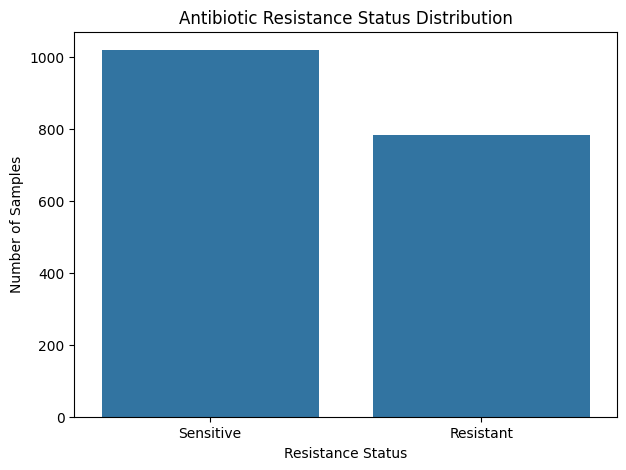

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='resistance_status'
)

plt.title('Antibiotic Resistance Status Distribution')
plt.xlabel('Resistance Status')
plt.ylabel('Number of Samples')
plt.show()

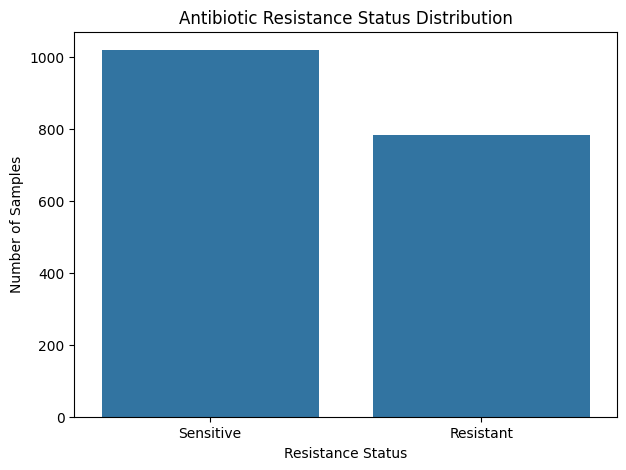

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='resistance_status'
)

plt.title('Antibiotic Resistance Status Distribution')
plt.xlabel('Resistance Status')
plt.ylabel('Number of Samples')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Input features
X = df.drop(['sample_id', 'resistance_status'], axis=1)

# Target variable
y = df['resistance_status']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

print("\nTotal Samples:", len(df))

Input Features:
                bacteria    antibiotic specimen_type         country  \
0    Salmonella enterica   Ceftriaxone        Sputum          Brazil   
1  Klebsiella pneumoniae    Gentamicin         Wound           India   
2    Salmonella enterica    Ampicillin         Blood          Brazil   
3  Staphylococcus aureus    Gentamicin         Blood  United Kingdom   
4       Escherichia coli  Tetracycline         Wound          Brazil   

   collection_year  
0             2024  
1             2023  
2             2023  
3             2022  
4             2018  

Target Values:
0    Sensitive
1    Sensitive
2    Resistant
3    Sensitive
4    Resistant
Name: resistance_status, dtype: object

Total Samples: 1800


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()
num_cols = X.select_dtypes(include=['number']).columns.tolist()

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('cat', categorical_transformer, cat_cols),
    ('num', numerical_transformer, num_cols)
])

print("Categorical Columns:", cat_cols)
print("Numerical Columns:", num_cols)

TypeError: string dtypes are not allowed, use 'object' instead

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()
num_cols = X.select_dtypes(include=['number']).columns.tolist()

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('cat', categorical_transformer, cat_cols),
    ('num', numerical_transformer, num_cols)
])

print("Categorical Columns:", cat_cols)
print("Numerical Columns:", num_cols)
print("Preprocessing Created Successfully!")

Categorical Columns: ['bacteria', 'antibiotic', 'specimen_type', 'country']
Numerical Columns: ['collection_year']
Preprocessing Created Successfully!


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1440, 5)
Testing Data: (360, 5)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label='Resistant', zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label='Resistant', zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label='Resistant', zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1
    })

    print(name, "Training Completed!")

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(results_df.round(4))

Logistic Regression Training Completed!
Decision Tree Training Completed!
Random Forest Training Completed!

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.6472,0.6629,0.3782,0.4816
1,Decision Tree,0.5472,0.4765,0.4551,0.4656
2,Random Forest,0.5556,0.4828,0.3590,0.4118


In [ ]:
from sklearn.metrics import classification_report

for name, pipeline in models.items():
    # আগের ধাপের trained pipeline ব্যবহার করার জন্য
    pass

In [ ]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "Ready!")

Logistic Regression Ready!
Decision Tree Ready!
Random Forest Ready!


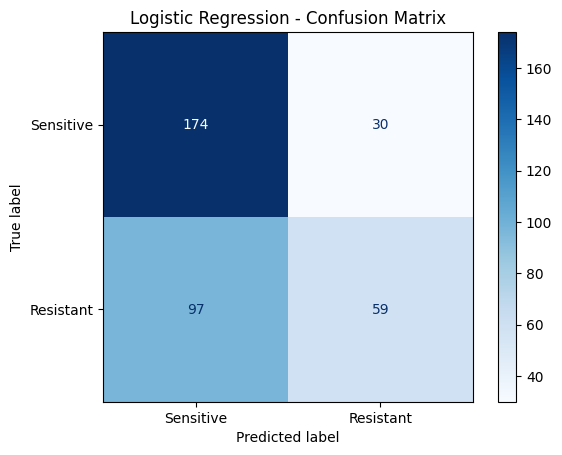

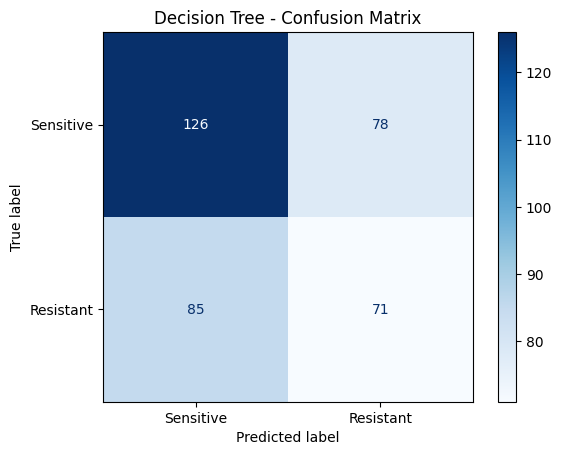

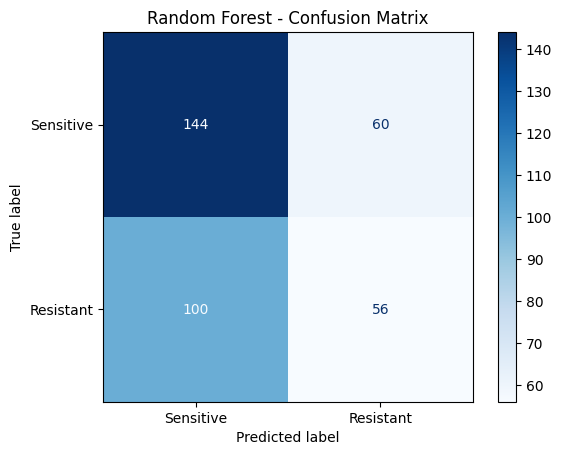

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=['Sensitive', 'Resistant']
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Sensitive', 'Resistant']
    )

    display.plot(cmap='Blues')
    plt.title(name + " - Confusion Matrix")
    plt.show()

In [ ]:
from sklearn.metrics import classification_report

for name, pipeline in trained_models.items():

    print("\n", name)
    y_pred = pipeline.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


 Logistic Regression
              precision    recall  f1-score   support

   Resistant       0.66      0.38      0.48       156
   Sensitive       0.64      0.85      0.73       204

    accuracy                           0.65       360
   macro avg       0.65      0.62      0.61       360
weighted avg       0.65      0.65      0.62       360


 Decision Tree
              precision    recall  f1-score   support

   Resistant       0.48      0.46      0.47       156
   Sensitive       0.60      0.62      0.61       204

    accuracy                           0.55       360
   macro avg       0.54      0.54      0.54       360
weighted avg       0.54      0.55      0.55       360


 Random Forest
              precision    recall  f1-score   support

   Resistant       0.48      0.36      0.41       156
   Sensitive       0.59      0.71      0.64       204

    accuracy                           0.56       360
   macro avg       0.54      0.53      0.53       360
weighted avg       0

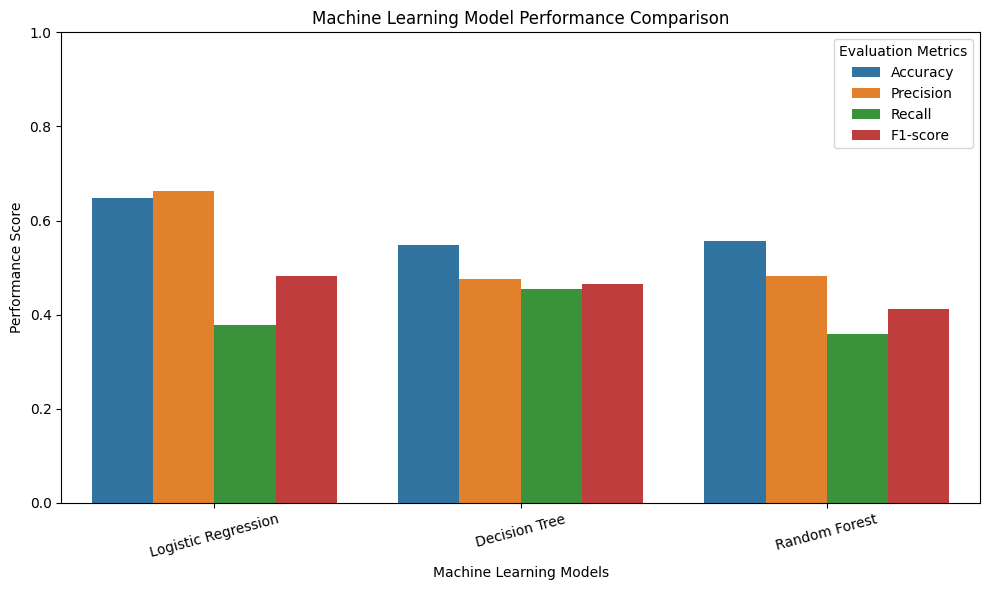

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

results_melted = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

sns.barplot(
    data=results_melted,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Machine Learning Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Performance Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

In [ ]:
best_model = results_df.loc[
    results_df['F1-score'].idxmax()
]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model        Logistic Regression
Accuracy                0.647222
Precision               0.662921
Recall                  0.378205
F1-score                0.481633
Name: 0, dtype: object


In [ ]:
results_df.to_csv(
    'model_comparison.csv',
    index=False
)

from google.colab import files
files.download('model_comparison.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

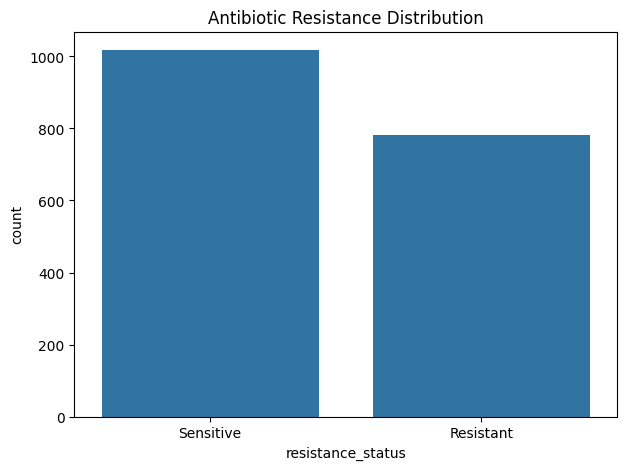

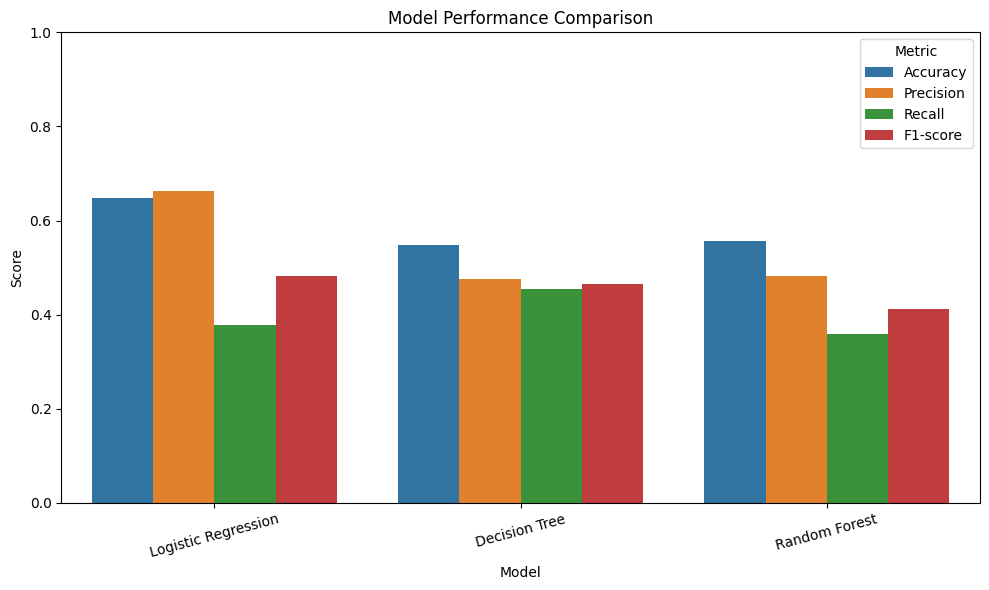

Graphs Saved Successfully!


In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("outputs", exist_ok=True)

# Resistance distribution
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='resistance_status')
plt.title('Antibiotic Resistance Distribution')
plt.savefig('outputs/label_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Model comparison
plt.figure(figsize=(10,6))
sns.barplot(data=results_melted, x='Model', y='Score', hue='Metric')
plt.title('Model Performance Comparison')
plt.ylim(0,1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('outputs/model_comparison.png', dpi=300)
plt.show()

print("Graphs Saved Successfully!")


In [ ]:
import joblib

for name, pipeline in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(pipeline, f"outputs/{filename}")

print("All Models Saved Successfully!")

All Models Saved Successfully!


In [ ]:
import shutil

shutil.make_archive("Antibiotic_Resistance_Project", "zip", ".")

from google.colab import files
files.download("Antibiotic_Resistance_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>